# 04 - PCA and maps of the players

**Goal of this notebook:** draw the players on a 2D map to *see* how they relate, using PCA, and look at the official positions and the K-Means groups on that same map.

Steps:
1. Fit PCA on the scaled features (9 features give 9 principal components).
2. See how much information each component keeps and what each one means.
3. Draw the map, colored by official position and by K-Means group.
4. Save the coordinates for the next notebook (and for Tableau).

**Input:** `data/processed/players_scaled.csv`, `data/processed/cluster_labels.csv`
**Output:** `data/processed/pca_coordinates.csv`

## 1. Imports and settings

`PCA` is in `sklearn.decomposition`. The colors below follow a fixed palette checked for color-blind readers. With five categories a single scatter plot with five colors would be hard to read, so for positions (and for k=5) we draw **one small panel per category**, highlighting that category over all the other players in gray.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

SCALED_PATH = Path("../data/processed/players_scaled.csv")
LABELS_PATH = Path("../data/processed/cluster_labels.csv")
PCA_PATH = Path("../data/processed/pca_coordinates.csv")

META_COLUMNS = ["player_id", "player", "team", "position", "games", "minutes_per_game"]
POSITION_ORDER = ["PG", "SG", "SF", "PF", "C"]

K_COLORED = 3  # one plot with a color per group (3 colors are safe to tell apart)
K_FACETED = 5  # one small panel per group

LABELED_PLAYERS = [
    "Nikola Jokić", "Luka Dončić", "Stephen Curry", "Giannis Antetokounmpo",
    "Rudy Gobert", "Victor Wembanyama", "Draymond Green",
]

In [2]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # first three slots of the categorical palette
NEGATIVE = "#e34948"
HIGHLIGHT = SERIES[0]

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "text.color": INK,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## 2. Load and combine

The scaled features come from notebook 02 and the group of every player from notebook 03. We join them by `player_id`, never by name.

In [3]:
df = pd.read_csv(SCALED_PATH)
labels = pd.read_csv(LABELS_PATH)

FEATURES = [col for col in df.columns if col.endswith("_per36")]
label_columns = [col for col in labels.columns if col.startswith("kmeans_k")]

df = df.merge(labels[["player_id"] + label_columns], on="player_id", validate="one_to_one")
X = df[FEATURES].to_numpy()
X.shape

(325, 9)

## 3. Fit PCA

With `n_components` equal to the number of features we keep all 9 components for now, ordered from the one that captures most of the spread of the players to the one that captures the least. `fit_transform` learns the weights and gives every player's value in each new component.

In [4]:
pca = PCA(n_components=len(FEATURES))
pcs = pca.fit_transform(X)
type(pcs), pcs.shape

(numpy.ndarray, (325, 9))

In [5]:
PC_COLUMNS = [f"PC{i + 1}" for i in range(len(FEATURES))]
df_pcs = pd.DataFrame(pcs, columns=PC_COLUMNS, index=df.index)
df = pd.concat([df, df_pcs], axis=1)
df_pcs.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
0,1.633009,0.458503,0.928948,-1.367764,0.241024,-0.013988,0.213773,-0.056267,0.209359
1,1.033810,1.873582,-1.329858,-0.035863,-0.093025,0.655197,-0.120032,-0.276575,-0.541652
2,-0.166567,0.905144,-0.461413,-0.894106,-0.172704,0.392033,0.095390,-0.143997,0.338335
3,-1.574118,-0.727956,-0.180139,0.456789,0.030354,-0.268068,0.619900,-0.204453,-0.060354
4,-0.405358,-1.227250,-1.479026,0.264295,-0.044974,-0.116519,-0.423818,-0.016483,-0.151690


Two checks. The new columns should be **uncorrelated** with each other (correlation matrix equal to the identity: 1 on the diagonal, 0 elsewhere), and their spread should be exactly what PCA reports.

In [6]:
np.allclose(np.corrcoef(pcs.T), np.eye(len(FEATURES)))

True

In [7]:
np.allclose(pcs.var(axis=0, ddof=1), pca.explained_variance_)

True

## 4. How much does each component keep?

`explained_variance_ratio_` is the share of the total spread captured by each component. The cumulative sum tells us how much of the original information survives if we keep only the first few.

In [8]:
variance = pd.DataFrame({
    "explained": pca.explained_variance_ratio_,
    "cumulative": pca.explained_variance_ratio_.cumsum(),
}, index=PC_COLUMNS)
variance.round(3)

,explained,cumulative
PC1,0.322,0.322
PC2,0.297,0.619
PC3,0.125,0.743
PC4,0.076,0.819
PC5,0.065,0.884
PC6,0.047,0.932
PC7,0.026,0.958
PC8,0.023,0.980
PC9,0.020,1.000


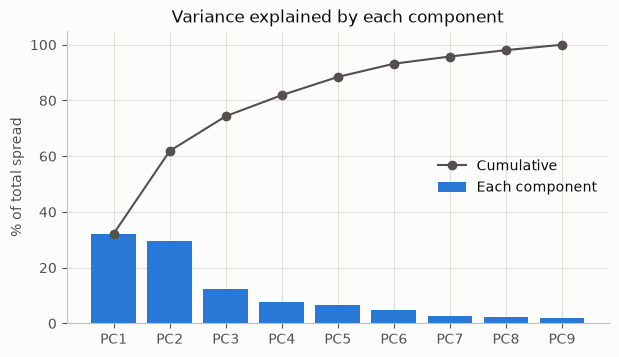

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(PC_COLUMNS, variance["explained"] * 100, color=HIGHLIGHT, label="Each component")
ax.plot(PC_COLUMNS, variance["cumulative"] * 100, color=INK_SECONDARY, marker="o", label="Cumulative")
ax.set_ylabel("% of total spread")
ax.set_ylim(0, 105)
ax.set_title("Variance explained by each component")
ax.legend(frameon=False, loc="center right");

## 5. What does each component mean?

Each component is a weighted sum of the 9 features. The weights (called *loadings*) tell us what the component measures: a large positive weight means a player with a lot of that stat gets a high value, and a negative weight pushes the other way. The **sign of a whole component is arbitrary** (PCA could return it flipped), what matters is which features point in opposite directions.

In [10]:
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=PC_COLUMNS)
loadings[["PC1", "PC2", "PC3"]].round(2)

,PC1,PC2,PC3
fg2a_per36,0.42,0.32,-0.11
fg3a_per36,-0.38,0.23,-0.27
fta_per36,0.35,0.36,-0.24
orb_per36,0.40,-0.35,0.14
drb_per36,0.46,-0.13,-0.05
ast_per36,0.06,0.49,0.28
stl_per36,-0.03,0.07,0.87
blk_per36,0.36,-0.30,-0.03
tov_per36,0.23,0.50,0.05


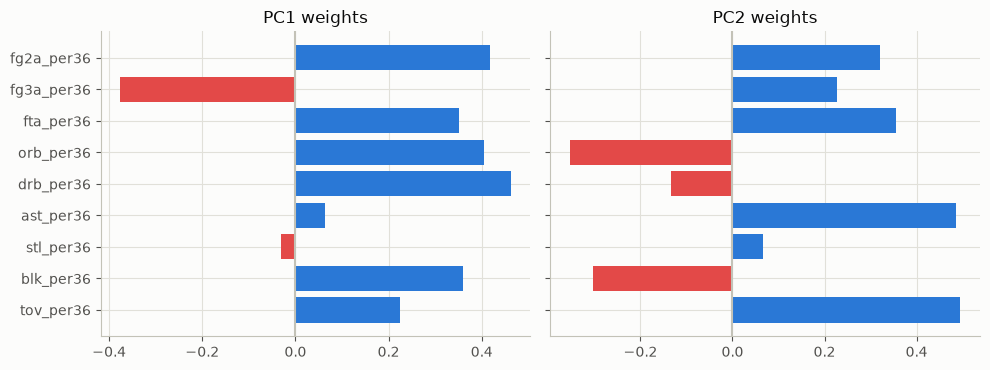

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, pc in zip(axes, ["PC1", "PC2"]):
    values = loadings[pc]
    ax.barh(values.index, values, color=[HIGHLIGHT if v >= 0 else NEGATIVE for v in values])
    ax.axvline(0, color=BASELINE)
    ax.set_title(f"{pc} weights")
axes[0].invert_yaxis()
fig.tight_layout()

**Reading them:**

- **PC1** has positive weights on rebounds (offensive and defensive), blocks, 2-point attempts and free throws, and a negative weight on 3-point attempts. It separates players who live close to the basket from players who shoot from outside: *interior vs perimeter*.
- **PC2** has positive weights on assists, turnovers, free throws and 2-point attempts, and negative weights on offensive rebounds and blocks. It separates players who handle the ball and create from players who finish near the rim: *creation vs rim running*.
- **PC3** is almost only steals. We leave it out of the map.

How much do the first two keep? About 62% of the total spread (32% + 30%). The remaining 38% is in the other components, so two players that look close on the map can still differ in them.

## 6. The maps

A helper to label a few well-known players, so we can orient ourselves on the map.

In [12]:
def label_players(ax, data, names):
    for _, row in data[data["player"].isin(names)].iterrows():
        ax.annotate(
            row["player"].split()[-1],
            (row["PC1"], row["PC2"]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
            color=INK_SECONDARY,
        )


def axis_labels(ax):
    ax.set_xlabel(f"PC1: interior vs perimeter ({pca.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"PC2: creation vs rim running ({pca.explained_variance_ratio_[1]:.0%})")

### 6.1 All players, no colors

Before coloring anything, the raw shape of the cloud.

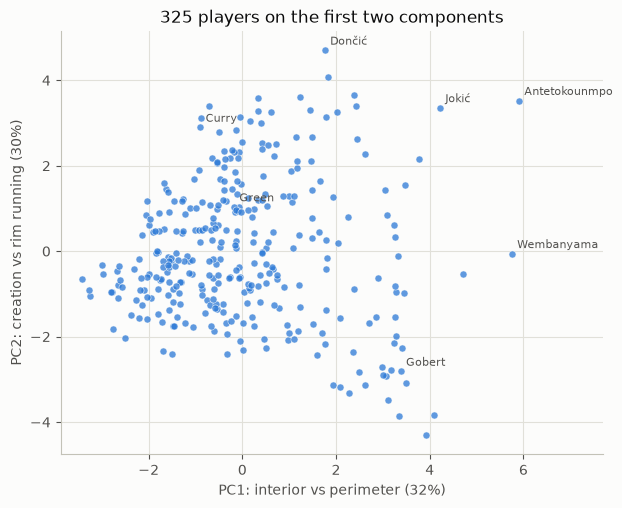

In [13]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(df["PC1"], df["PC2"], s=26, color=HIGHLIGHT, alpha=0.75, edgecolors=SURFACE, linewidths=0.5)
label_players(ax, df, LABELED_PLAYERS)
axis_labels(ax)
ax.set_xlim(right=df["PC1"].max() + 1.8)  # room for the names on the right
ax.set_title("325 players on the first two components");

### 6.2 By official position

One panel per position: the highlighted dots are that position, the gray ones are everybody else. If a position were a clear style, its dots would sit together in one region.

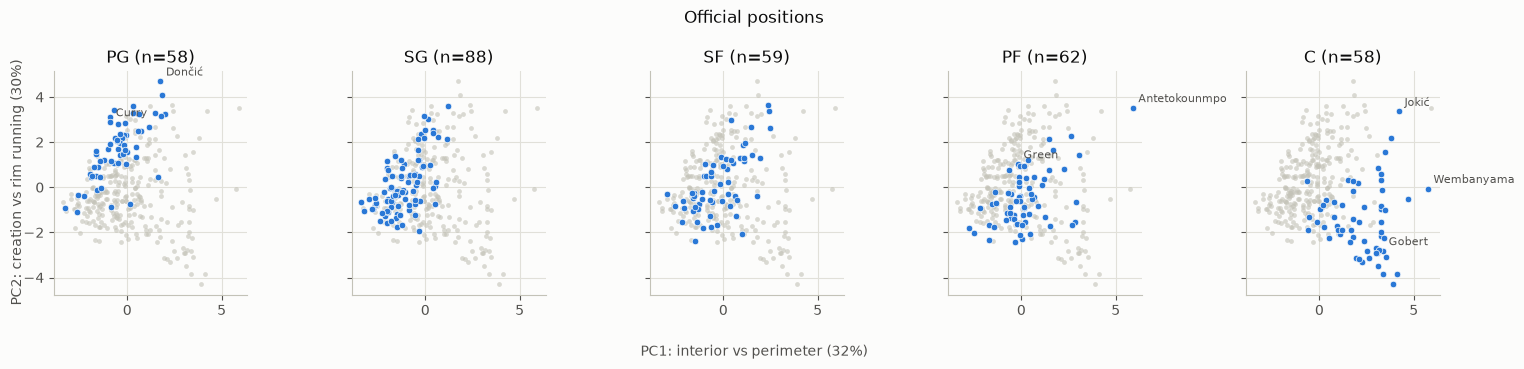

In [14]:
def plot_panels(data, column, categories, title, names=None):
    fig, axes = plt.subplots(1, len(categories), figsize=(3.1 * len(categories), 3.6), sharex=True, sharey=True)
    for ax, category in zip(axes, categories):
        mask = data[column] == category
        ax.scatter(data.loc[~mask, "PC1"], data.loc[~mask, "PC2"], s=12, color=BASELINE, alpha=0.6, linewidths=0)
        ax.scatter(data.loc[mask, "PC1"], data.loc[mask, "PC2"], s=22, color=HIGHLIGHT, edgecolors=SURFACE, linewidths=0.5)
        ax.set_title(f"{category} (n={mask.sum()})")
        if names:
            label_players(ax, data[mask], names)
    fig.supxlabel(f"PC1: interior vs perimeter ({pca.explained_variance_ratio_[0]:.0%})", fontsize=10, color=INK_SECONDARY)
    fig.supylabel(f"PC2: creation vs rim running ({pca.explained_variance_ratio_[1]:.0%})", fontsize=10, color=INK_SECONDARY)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


fig = plot_panels(df, "position", POSITION_ORDER, "Official positions", names=LABELED_PLAYERS)

### 6.3 By K-Means group, k=3

With three groups, one plot with one color each is readable. The group numbers are arbitrary labels from K-Means; they do not mean "first" or "best".

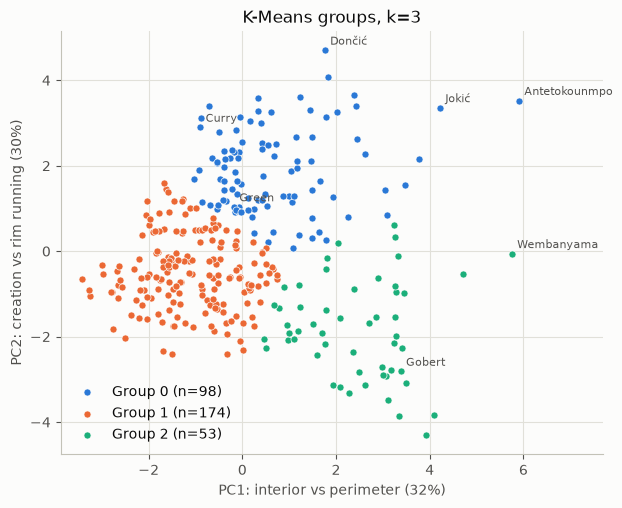

In [15]:
column = f"kmeans_k{K_COLORED}"
fig, ax = plt.subplots(figsize=(7, 5.5))
for cluster, color in zip(sorted(df[column].unique()), SERIES):
    subset = df[df[column] == cluster]
    ax.scatter(subset["PC1"], subset["PC2"], s=26, color=color, edgecolors=SURFACE, linewidths=0.5,
               label=f"Group {cluster} (n={len(subset)})")
label_players(ax, df, LABELED_PLAYERS)
axis_labels(ax)
ax.set_xlim(right=df["PC1"].max() + 1.8)  # room for the names on the right
ax.set_title(f"K-Means groups, k={K_COLORED}")
ax.legend(frameon=False);

### 6.4 By K-Means group, k=5

Same idea as the positions, so the two figures can be compared panel by panel.

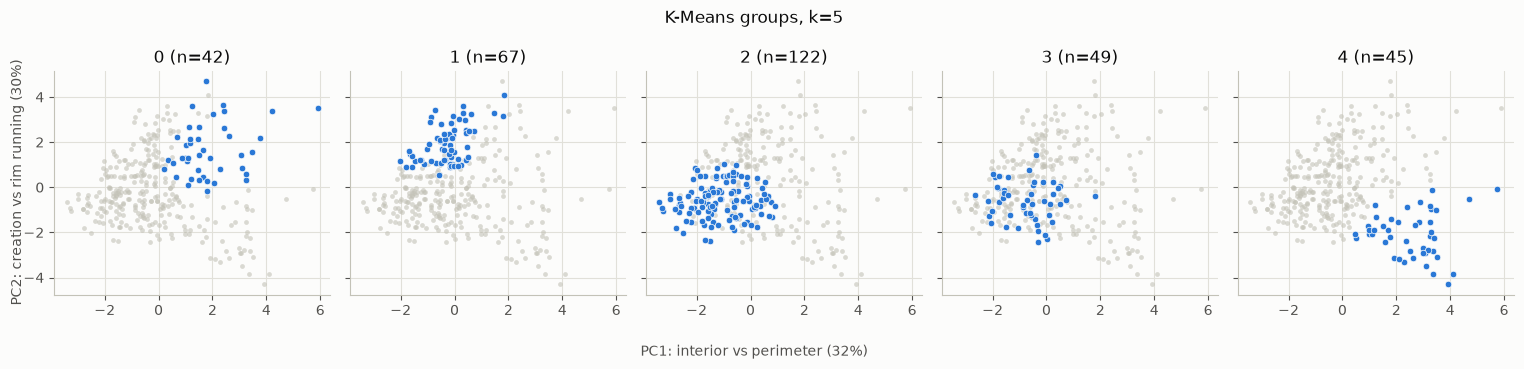

In [16]:
column = f"kmeans_k{K_FACETED}"
fig = plot_panels(df, column, sorted(df[column].unique()), f"K-Means groups, k={K_FACETED}")

## 7. Save

We save the first three coordinates and every K-Means label next to the identification columns. The next notebook uses it to describe each group, and the same file can be loaded into Tableau for an interactive version of these maps.

In [17]:
df_out = df[META_COLUMNS + PC_COLUMNS[:3] + label_columns]
df_out.to_csv(PCA_PATH, index=False)
df_out.shape

(325, 18)

## Summary

- PCA turned the 9 features into 9 uncorrelated components. The first two keep about 62% of the spread and have a clear meaning: PC1 is *interior vs perimeter*, PC2 is *creation vs rim running*.
- **Positions are not random on the map, but they overlap a lot.** Point guards sit mostly in the upper left (creation, perimeter) and centers in the lower right (interior, rim running). Shooting guards, small forwards and power forwards share most of the same crowded area on the left and center.
- **The upper right is a mix of official positions.** Players who are both interior and creators (Jokić, a center; Antetokounmpo, a power forward; Dončić, a point guard) share that region. That is the kind of overlap the project looks for.
- With k=3, K-Means splits the map into three regions: creators on top, rim runners at the lower right and everyone else on the left. With k=5 it cuts the big left and center crowd into more pieces, and neighboring groups touch, which fits the low silhouette seen in notebook 03.
- Caution: K-Means used the same features that PCA draws, so its groups *must* look like regions on this map. The informative contrast is with the official positions, which did not use those features.
- Next: describe each group with real numbers (not z-scores), name them, and compare them with the five positions in a table.